# 03 · Policies and the capital frontier (v2 world)

> **Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.** Falcon Hub Airways is fictional and every airline number below is SIMULATED by this repo's code: a simulated planning snapshot, not operator data. Provenance tags: **REAL** (public data), **DERIVED** (computed by code), **ASSUMED** (a config planning assumption), **SIMULATED** (simulator output).

**The decision.** How should Falcon Hub Airways position its spare parts across the AUH hub and six outstations? Three policies were frozen before the holdout:

* **Simple Rulebook (naive reference) `P0`:** provisioning on the supplier's quoted data. A Poisson protection level at AUH, plus a line-station unit only where a D0 part has at least 4 quoted removals a year at that station. It holds only 8 outstation rotables: a deliberately simplified starting point, not a model of a competent airline.
* **Each Airport for Itself (simplified local comparator) `P1`:** each station sized on its own, from the history-based forecasts.
* **Network Plan `P2`:** the same forecasts, but positioned as a network: a pooled hub float plus outstation units where the value of avoiding a D0 miss (hub transfer, local borrow, exchange/loan odds, the hourly rate and the fixed cost per event) justifies the holding cost.

**Core finding: Network Plan `P2`.** Network positioning cuts material AOG hours against the Simple Rulebook `P0` by a large, significant amount for a small amount of extra capital, in all three worlds and across the ×0.5–×2 hourly-rate range (section 1). **Frontier option: Network Plan + Extra Spares `I125`.** If the airline invests an additional AED 7.6M, the optimiser's recommended point cuts downtime further, with sensitivities that are shown, not hidden (sections 3–6).

Headline numbers come from the **v2 holdout** (seeds 2000–2019, never used for any choice), central world unless stated. Selection-seed numbers (100–119) are labelled as such. A v1 world was archived after a domain review; see `archive/v1`.

*across 120 modelled part numbers · simulated · downtime of the aircraft waiting for the part*

> How to read these numbers: simulated downtime of the aircraft waiting for the part, across 120 modelled part numbers. Downtime of aircraft that donated a part (cannibalisation) is shown separately, not included. The Simple Rulebook is a deliberately simplified starting point, not a model of a competent airline. Part costs, reliability and sourcing are assumed. These are not forecasts of achievable airline savings.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd()))            # notebooks/_style.py
import numpy as np, pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from _style import *                            # palette, ROOT, stamp(), aed_m(), load_json(), ci()
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
print("project root:", ROOT)
ps = load_json("outputs/holdout/policy_summary.json")
sel = load_json("outputs/policies/selection_summary.json")
kp = load_json("docs/data/kpis.json")
fs = load_json("outputs/frontier/summary.json")
cen = ps["variants"]["central"]
print(ps["split"], "seeds", ps["seeds"][0], "-", ps["seeds"][-1], "|", ps["ci_method"])
out = {}
for p in ["P0", "P1", "P2"]:
    sp = pd.read_csv(ROOT / f"outputs/policies/{p}_stock_params.csv")
    out[p] = int(sp[(sp.part_class == "R") & (sp.station != "AUH")].target_units.sum())
print("outstation rotable units at target (central plans):", out)
assert out == kp["headline"]["core"]["outstation_rotables"]

project root: /Users/akashgajjar/grounded-no-more
holdout seeds 2000 - 2019 | 95% paired t over seeds; bootstrap check
outstation rotable units at target (central plans): {'P0': 8, 'P1': 193, 'P2': 44}


## 1. Core finding: Network Plan `P2` against the Simple Rulebook `P0`, on the holdout

Means over 20 holdout seeds with 95% intervals; the paired differences use the same seeds and the same per-request random numbers for every policy, so they are much tighter than the raw intervals.

In [2]:
metrics = [("immediate_fill_rate", "fill", "{:.4f}", 1), ("aog_hours", "material AOG h/yr", "{:,.0f}", 1),
           ("aog_events", "AOG events/yr", "{:.1f}", 1), ("spare_capital_aed", "capital AED M", "{:.2f}", 1e6),
           ("total_annual_cost_aed", "total cost AED M/yr", "{:.2f}", 1e6), ("expedite_cost_aed", "AOG-route spend AED M/yr", "{:.2f}", 1e6)]
tab = pd.DataFrame({lab: {p: ci(cen["policies"][p][k], f, s) for p in ["P0", "P1", "P2"]} for k, lab, f, s in metrics})
tab.insert(0, "outstation rotables", pd.Series(out))
display(tab)
pair = pd.DataFrame({lab: {pr: ci(cen["paired"][pr][k], f, s, signed=True) for pr in ["P2-P0", "P1-P0", "P2-P1"]} for k, lab, f, s in metrics})
pair["seeds with lower AOG"] = [f"{cen['paired'][pr]['aog_hours']['share_seeds_better']:.0%}" for pr in pair.index]
print("Paired differences (mean [95% paired-t CI]):"); display(pair)
d = cen["paired"]["P2-P0"]
print(f"P2 vs P0: {ci(d['aog_hours'], signed=True)} material AOG h/yr for {ci(d['spare_capital_aed'], '{:.2f}', 1e6, signed=True)} AED M capital; "
      f"immediate fill {ci(d['immediate_fill_rate'], '{:.2f}', 0.01, signed=True)} pts")

,outstation rotables,fill,material AOG h/yr,AOG events/yr,capital AED M,total cost AED M/yr,AOG-route spend AED M/yr
P0,8,"0.9892 [0.9887, 0.9898]","1,690 [1,555, 1,826]","78.0 [73.9, 82.0]","48.43 [48.31, 48.55]","69.66 [65.67, 73.66]","1.70 [1.49, 1.92]"
P1,193,"0.9766 [0.9750, 0.9782]","566 [452, 680]","17.3 [14.6, 20.0]","71.89 [71.78, 71.99]","47.66 [44.28, 51.04]","0.87 [0.73, 1.00]"
P2,44,"0.9767 [0.9751, 0.9783]","210 [146, 274]","8.6 [6.7, 10.5]","49.05 [48.94, 49.16]","35.75 [33.44, 38.06]","1.61 [1.44, 1.78]"


Paired differences (mean [95% paired-t CI]):


,fill,material AOG h/yr,AOG events/yr,capital AED M,total cost AED M/yr,AOG-route spend AED M/yr,seeds with lower AOG
P2-P0,"-0.0125 [-0.0142, -0.0109]","-1,480 [-1,629, -1,332]","-69.3 [-73.9, -64.8]","+0.61 [+0.56, +0.67]","-33.91 [-37.91, -29.91]","-0.09 [-0.28, +0.10]",100%
P1-P0,"-0.0126 [-0.0143, -0.0110]","-1,125 [-1,254, -995]","-60.6 [-64.6, -56.7]","+23.46 [+23.40, +23.51]","-22.00 [-25.68, -18.33]","-0.84 [-1.03, -0.65]",100%
P2-P1,"+0.0001 [-0.0007, +0.0010]","-356 [-458, -254]","-8.7 [-10.9, -6.5]","-22.84 [-22.86, -22.82]","-11.91 [-14.58, -9.23]","+0.75 [+0.65, +0.85]",100%


P2 vs P0: -1,480 [-1,629, -1,332] material AOG h/yr for +0.61 [+0.56, +0.67] AED M capital; immediate fill -1.25 [-1.42, -1.09] pts


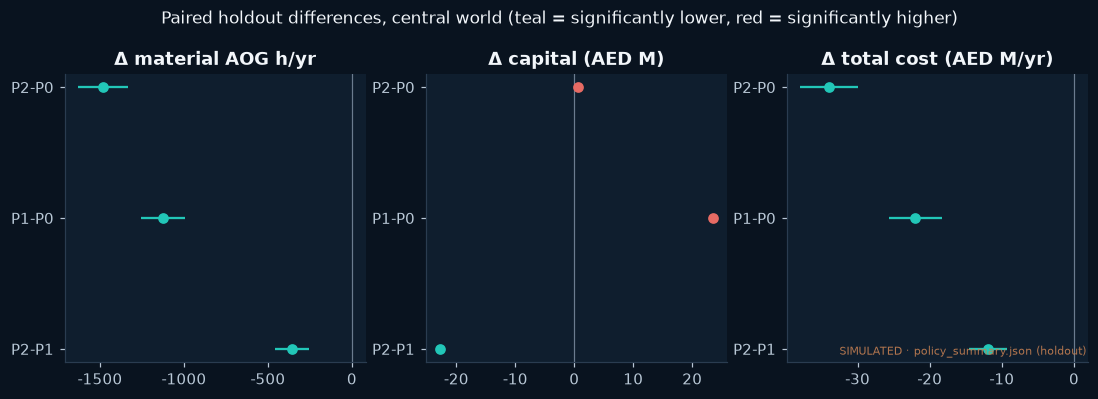

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
prs = ["P2-P0", "P1-P0", "P2-P1"]
for ax, (k, lab, scale) in zip(axes, [("aog_hours", "Δ material AOG h/yr", 1), ("spare_capital_aed", "Δ capital (AED M)", 1e6),
                                      ("total_annual_cost_aed", "Δ total cost (AED M/yr)", 1e6)]):
    for i, pr in enumerate(prs):
        dd = cen["paired"][pr][k]
        col = TEAL if dd["ci_hi"] < 0 else (RED if dd["ci_lo"] > 0 else TITANIUM)
        ax.errorbar(dd["mean"] / scale, i, xerr=[[(dd["mean"] - dd["ci_lo"]) / scale], [(dd["ci_hi"] - dd["mean"]) / scale]],
                    fmt="o", color=col, capsize=0, ms=6)
    ax.axvline(0, color=SLATE, lw=0.8); ax.set_yticks(range(3)); ax.set_yticklabels(prs); ax.invert_yaxis(); ax.set_title(lab)
fig.suptitle("Paired holdout differences, central world (teal = significantly lower, red = significantly higher)", color=ICE, y=1.05, fontsize=11)
stamp(axes[-1], "policy_summary.json (holdout)"); plt.show()

P2 removes most of P0's material AOG hours, on every holdout seed. The extra capital is small because P2 mostly *positions* rather than adds: it places 44 rotables at the outstations where D0 removals actually happen, sized from history-based removal rates instead of vendor quotes. P1, which optimises each station on its own, buys a smaller reduction for far more capital, and P2 beats it on downtime, capital and cost.

**The honest trade-off.** P1 and P2 have a slightly *lower* immediate fill than P0 (the fill row above). P0's consumable and expendable min/max levels (26/13 weeks of cover) are generous, so P0 fills more count-part requests from the shelf; P1/P2 stock C/E to a cycle service level. Those misses are cheap, because consumables are never D0 and expendables recover through local buy. The rotable fill moves the other way. It is reported, not tuned away:

In [4]:
bc = pd.DataFrame(ps["by_class"])
fill = bc[bc.variant == "central"].pivot(index="part_class", columns="policy_id", values="immediate_fill_rate")[["P0", "P1", "P2"]]
aogc = bc[bc.variant == "central"].pivot(index="part_class", columns="policy_id", values="aog_hours")[["P0", "P1", "P2"]]
display(pd.concat({"immediate fill": fill.round(4), "material AOG h/yr": aogc.round(0)}, axis=1))

immediate fill                 material AOG h/yr              
policy_id              P0      P1      P2                P0     P1     P2
part_class                                                               
C                  0.9999  0.9810  0.9833               0.0    4.0    0.0
E                  0.9487  0.9462  0.9178              21.0    7.0    1.0
R                  0.8034  0.9135  0.8980            1670.0  555.0  209.0

### Does P2 hold in all three worlds and across the hourly-rate range?

In the low- and high-stress worlds P1 and P2 are re-planned from each world's own history (`P2`), and the central-built plans are also evaluated unchanged (`P2@central`). The hourly-rate sensitivity scales only the hourly part of the downtime cost; the fixed cost per AOG event stays at ×1.

In [5]:
rows = []
for wv in ["low_stress", "central", "high_stress"]:
    v = ps["variants"][wv]
    for pr in [p for p in ["P2-P0", "P2@central-P0"] if p in v["paired"]]:
        dd = v["paired"][pr]
        rows.append(dict(world=wv, pair=pr, d_aog_h=ci(dd["aog_hours"], signed=True),
                         d_capital_M=ci(dd["spare_capital_aed"], "{:.2f}", 1e6, signed=True),
                         **{f"d_cost_M_{m}": ci(dd[f"total_cost_pen_{m}"], "{:.1f}", 1e6, signed=True) for m in ["x0.5", "x1", "x2"]},
                         significant_all=all(dd[k]["ci_hi"] < 0 for k in ["aog_hours", "total_cost_pen_x0.5", "total_cost_pen_x1", "total_cost_pen_x2"])))
wt = pd.DataFrame(rows); display(wt)
assert wt.significant_all.all()

,world,pair,d_aog_h,d_capital_M,d_cost_M_x0.5,d_cost_M_x1,d_cost_M_x2,significant_all
0,low_stress,P2-P0,"-1,263 [-1,443, -1,084]","-0.97 [-1.03, -0.91]","-15.7 [-18.2, -13.2]","-28.3 [-33.0, -23.7]","-53.6 [-62.5, -44.7]",True
1,low_stress,P2@central-P0,"-1,334 [-1,492, -1,175]","+0.69 [+0.62, +0.75]","-16.8 [-18.8, -14.8]","-30.4 [-34.1, -26.7]","-57.7 [-64.8, -50.6]",True
2,central,P2-P0,"-1,480 [-1,629, -1,332]","+0.61 [+0.56, +0.67]","-19.0 [-21.2, -16.8]","-33.9 [-37.9, -29.9]","-63.8 [-71.4, -56.2]",True
3,high_stress,P2-P0,"-1,619 [-1,800, -1,438]","+2.97 [+2.87, +3.06]","-20.9 [-23.4, -18.5]","-37.5 [-41.9, -33.0]","-70.6 [-79.1, -62.1]",True
4,high_stress,P2@central-P0,"-1,566 [-1,749, -1,382]","+0.54 [+0.45, +0.64]","-20.3 [-22.7, -17.9]","-36.2 [-40.5, -31.8]","-67.9 [-76.2, -59.5]",True


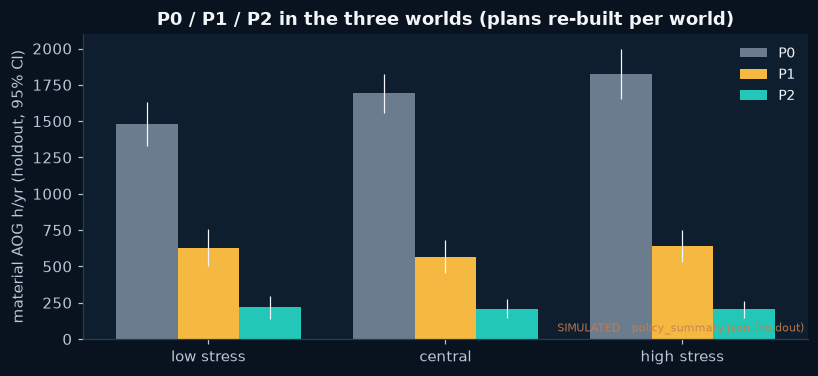

In [6]:
fig, ax = plt.subplots(figsize=(8.5, 3.6))
worlds = ["low_stress", "central", "high_stress"]
for j, p in enumerate(["P0", "P1", "P2"]):
    m = [ps["variants"][w]["policies"][p]["aog_hours"] for w in worlds]
    x = np.arange(3) + (j - 1) * 0.26
    ax.bar(x, [d["mean"] for d in m], width=0.26, color=POLICY_COLORS[p], label=p,
           yerr=[[d["mean"] - d["ci_lo"] for d in m], [d["ci_hi"] - d["mean"] for d in m]], error_kw=dict(ecolor=ICE, lw=0.8))
ax.set_xticks(range(3)); ax.set_xticklabels(["low stress", "central", "high stress"])
ax.set(ylabel="material AOG h/yr (holdout, 95% CI)", title="P0 / P1 / P2 in the three worlds (plans re-built per world)")
ax.legend(frameon=False); stamp(ax, "policy_summary.json (holdout)"); plt.show()

The P2 advantage is significant in every world and at ×0.5, ×1 and ×2 the hourly rate, for both the re-planned and the central-built P2.

### Selection → holdout consistency

The selection seeds were used to build and choose; the holdout was run once after the freeze. If the selection numbers sit inside the holdout intervals, the choices were not fitted to noise:

In [7]:
rows = []
for p in ["P0", "P1", "P2"]:
    for k in ["immediate_fill_rate", "aog_hours", "spare_capital_aed"]:
        h, s = cen["policies"][p][k], sel["variants"]["central"]["policies"][p][k]
        rows.append(dict(policy=p, metric=k, selection=s["mean"], holdout=h["mean"], holdout_ci=(round(h["ci_lo"], 4), round(h["ci_hi"], 4)),
                         selection_inside_holdout_ci=h["ci_lo"] <= s["mean"] <= h["ci_hi"]))
cons = pd.DataFrame(rows); display(cons.round(4))
fsel = pd.read_csv(ROOT / "outputs/frontier/selection_points.csv").query("variant == 'central'").set_index("id")
fp = pd.read_csv(ROOT / "outputs/holdout/frontier_points.csv").set_index("id")
common = sorted(fsel.index.intersection(fp.index))
sm, hl, hh = (fsel.loc[common, "aog_hours_mean"].to_numpy(), fp.loc[common, "aog_hours_lo"].to_numpy(), fp.loc[common, "aog_hours_hi"].to_numpy())
inside = (sm >= hl) & (sm <= hh)
rho = np.corrcoef(np.log(fsel.loc[common, "aog_hours_mean"]), np.log(fp.loc[common, "aog_hours_mean"]))[0, 1]
print(f"policies: {cons.selection_inside_holdout_ci.sum()} of {len(cons)} selection means inside the holdout CI")
print(f"frontier candidates: {inside.sum()} of {len(common)} selection AOG means inside the holdout CI; log-AOG correlation selection vs holdout r = {rho:.3f}")

,policy,metric,selection,holdout,holdout_ci,selection_inside_holdout_ci
0,P0,immediate_fill_rate,9.893000e-01,9.892000e-01,"(0.9887, 0.9898)",True
1,P0,aog_hours,1.727350e+03,1.690500e+03,"(1554.8262, 1826.1738)",True
2,P0,spare_capital_aed,4.846491e+07,4.843269e+07,"(48312896.3335, 48552490.5836)",True
3,P1,immediate_fill_rate,9.764000e-01,9.766000e-01,"(0.975, 0.9782)",True
4,P1,aog_hours,5.452500e+02,5.659000e+02,"(451.5314, 680.2686)",True
5,P1,spare_capital_aed,7.189812e+07,7.188828e+07,"(71781942.2971, 71994619.8234)",True
6,P2,immediate_fill_rate,9.767000e-01,9.767000e-01,"(0.9751, 0.9783)",True
7,P2,aog_hours,2.352500e+02,2.101500e+02,"(146.0315, 274.2685)",True
8,P2,spare_capital_aed,4.908543e+07,4.904768e+07,"(48938385.2577, 49156972.4627)",True


policies: 9 of 9 selection means inside the holdout CI
frontier candidates: 23 of 25 selection AOG means inside the holdout CI; log-AOG correlation selection vs holdout r = 0.999


## 2. Hub vs outstation

Where is the downtime, and where does P2 remove it? Holdout material AOG hours by station (central world), with the paired P2 − P0 difference per station:

policy_id,P0,P1,P2,P2-P0 [95% CI],robberies/yr P0 → P2
station,,,,,
AUH,509.0,557.0,180.0,"-329 [-406, -252]",33.2 → 22.4
LHR,161.0,2.0,8.0,"-153 [-192, -113]",0.0 → 0.0
FRA,136.0,2.0,3.0,"-133 [-170, -97]",0.0 → 0.0
CAI,284.0,2.0,2.0,"-282 [-318, -246]",0.0 → 0.0
JED,228.0,2.0,3.0,"-225 [-274, -175]",0.0 → 0.0
BOM,242.0,0.0,6.0,"-236 [-271, -200]",0.0 → 0.0
SIN,131.0,1.0,8.0,"-123 [-144, -102]",0.0 → 0.0


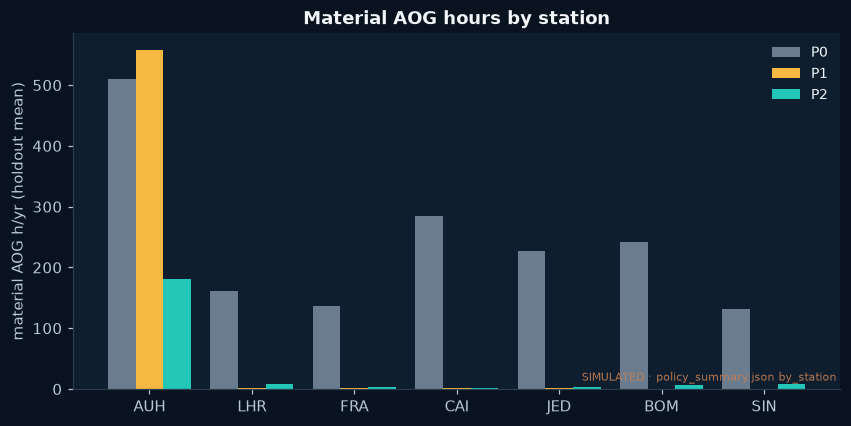

hub share of material AOG hours: P0 30%, P2 86%; outstation hours P0 1,181 -> P2 30


In [8]:
bs = pd.DataFrame([r for r in ps["by_station"] if r["variant"] == "central"])
order = ["AUH", "LHR", "FRA", "CAI", "JED", "BOM", "SIN"]
piv = bs.pivot(index="station", columns="policy_id", values="aog_hours").reindex(order)[["P0", "P1", "P2"]]
pbs = pd.DataFrame([r for r in ps["paired_by_station"] if r["variant"] == "central" and r["pair"] == "P2-P0" and r["metric"] == "aog_hours"]).set_index("station").reindex(order)
piv["P2-P0 [95% CI]"] = [f"{m:+.0f} [{lo:+.0f}, {hi:+.0f}]" for m, lo, hi in zip(pbs["mean"], pbs.ci_lo, pbs.ci_hi)]
routes = bs[bs.policy_id.isin(["P0", "P2"])].pivot(index="station", columns="policy_id", values="route_robbery_per_year").reindex(order)
piv["robberies/yr P0 → P2"] = [f"{a:.1f} → {b:.1f}" for a, b in zip(routes.P0, routes.P2)]
display(piv.round(0))
fig, ax = plt.subplots()
x = np.arange(len(piv)); wd = 0.27
for i, p in enumerate(["P0", "P1", "P2"]):
    ax.bar(x + (i - 1) * wd, piv[p], width=wd, color=POLICY_COLORS[p], label=p)
ax.set_xticks(x); ax.set_xticklabels(piv.index); ax.set(ylabel="material AOG h/yr (holdout mean)", title="Material AOG hours by station")
ax.legend(frameon=False); stamp(ax, "policy_summary.json by_station"); plt.show()
hub = piv.loc["AUH", ["P0", "P2"]] / piv[["P0", "P2"]].sum()
print(f"hub share of material AOG hours: P0 {hub.P0:.0%}, P2 {hub.P2:.0%}; outstation hours P0 {piv.loc[order[1:], 'P0'].sum():,.0f} -> P2 {piv.loc[order[1:], 'P2'].sum():,.0f}")

Under P0 most downtime sits at the **outstations**: D0 removals there find an empty shelf and wait for a hub transfer or a local borrow (PS1 in notebook 01 is the clearest case). P2's 44 outstation rotables remove most of it, and the pooled hub float also improves, so robbery at AUH (which needs engineering/quality approval) is needed less often.

## 3. The capital frontier: P2 as the core, I125 as the frontier option

25 frozen candidates (P0/P1/P2, budget points B015–B250 re-optimised from scratch, 'P2 within guardrails + greedy additions' points I110/I125, a repositioning and TAT levers) were simulated on the holdout. The recommendation rule was stated before computing and applied on the selection seeds: walk up the lower convex hull of capital vs downtime, and stop where the next segment's downtime reduction per extra AED 1M falls below the break-even h* implied by the holding cost and the realised cost per downtime hour.

rule (selection): h* = 6.42 downtime h per AED 1M (AED 31,151 per downtime h, carry 20%) -> I125


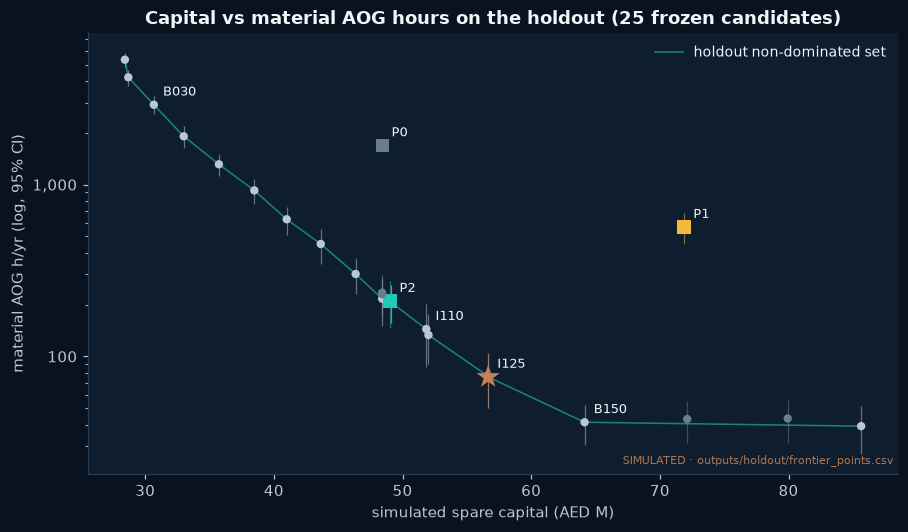

In [9]:
rec = fs["recommendation"]
fr_site = load_json("docs/data/frontier.json")
dom = {p["id"]: p["dominated"] for p in fr_site["points"]}
print(f"rule (selection): h* = {rec['h_star_per_aed_1m']:.2f} downtime h per AED 1M (AED {rec['aed_per_aog_hour']:,.0f} per downtime h, "
      f"carry {rec['carrying_pct']:.0%}) -> {rec['recommended']}")
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for pid, r in fp.iterrows():
    x, y = r.capital_mean / 1e6, r.aog_hours_mean
    if pid in ("P0", "P1", "P2"):
        col, mk, sz = POLICY_COLORS[pid], "s", 80
    elif pid == rec["recommended"]:
        col, mk, sz = COPPER, "*", 260
    else:
        col, mk, sz = (TITANIUM if not dom.get(pid, False) else SLATE), "o", 30
    ax.errorbar(x, y, yerr=[[y - r.aog_hours_lo], [r.aog_hours_hi - y]], fmt="none", ecolor=col, alpha=0.5, lw=0.8)
    ax.scatter(x, y, color=col, marker=mk, s=sz, zorder=3, edgecolor="none")
    if pid in ("P0", "P1", "P2", rec["recommended"], "I110", "B150", "B030"):
        ax.annotate(pid, (x, y), xytext=(6, 6), textcoords="offset points", color=ICE, fontsize=8.5)
nd = fp.loc[[k for k in fp.index if not dom.get(k, True)]].sort_values("capital_mean")
ax.plot(nd.capital_mean / 1e6, nd.aog_hours_mean, color=TEAL, lw=1, alpha=0.6, label="holdout non-dominated set")
ax.set(yscale="log", xlabel="simulated spare capital (AED M)", ylabel="material AOG h/yr (log, 95% CI)",
       title="Capital vs material AOG hours on the holdout (25 frozen candidates)")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False, loc="upper right"); stamp(ax, "outputs/holdout/frontier_points.csv"); plt.show()

In [10]:
keep = ["P0", "P1", "P2", "P2_GUARD", "B100", "I110", "I125", "B150", "B200", "LEV_TAT10_TOP6"]
ft = fp.loc[[k for k in keep if k in fp.index], ["capital_mean", "aog_hours_mean", "aog_hours_lo", "aog_hours_hi", "d_aog_hours_vs_base_mean",
                   "d_aog_hours_vs_base_lo", "d_aog_hours_vs_base_hi", "total_cost_mean", "fill_rate_mean", "aog_events_mean"]].copy()
for c in ["capital_mean", "total_cost_mean"]:
    ft[c] = ft[c] / 1e6
ft["dominated_on_holdout"] = [dom.get(k) for k in ft.index]
print("Holdout; d_* columns are paired differences vs P2 (the base policy):"); display(ft.round(2))
i = fp.loc["I125"]
fo = kp["headline"]["frontier_option"]
print(f"I125 vs P2 (paired, holdout): {i.d_aog_hours_vs_base_mean:+.0f} material AOG h/yr [{i.d_aog_hours_vs_base_lo:+.0f}, {i.d_aog_hours_vs_base_hi:+.0f}] "
      f"for an additional {aed_m(i.d_capital_vs_base_mean)} of capital; total cost {aed_m(i.d_total_cost_vs_base_mean)}/yr "
      f"[{aed_m(i.d_total_cost_vs_base_lo)}, {aed_m(i.d_total_cost_vs_base_hi)}]")
assert abs(i.d_capital_vs_base_mean - fo["extra_capital_aed"]["mean"]) < 1 and abs(-i.d_aog_hours_vs_base_mean - fo["aog_reduction"]["mean"]) < 0.06
b = fp.loc["B150"]
print(f"next hull step on the holdout, I125 -> B150: {i.aog_hours_mean - b.aog_hours_mean:.0f} h/yr fewer for {aed_m(b.capital_mean - i.capital_mean)} more "
      f"= {(i.aog_hours_mean - b.aog_hours_mean) / ((b.capital_mean - i.capital_mean) / 1e6):.1f} h per AED 1M (break-even h* = {rec['h_star_per_aed_1m']:.1f})")

Holdout; d_* columns are paired differences vs P2 (the base policy):


,capital_mean,aog_hours_mean,aog_hours_lo,aog_hours_hi,d_aog_hours_vs_base_mean,d_aog_hours_vs_base_lo,d_aog_hours_vs_base_hi,total_cost_mean,fill_rate_mean,aog_events_mean,dominated_on_holdout
id,,,,,,,,,,,
P0,48.43,1690.50,1554.83,1826.17,1480.35,1332.02,1628.68,69.66,0.99,77.95,True
P1,71.89,565.90,451.53,680.27,355.75,253.96,457.54,47.66,0.98,17.30,True
P2,49.05,210.15,146.03,274.27,0.00,0.00,0.00,35.75,0.98,8.60,False
P2_GUARD,48.42,230.70,164.34,297.06,20.55,13.83,27.27,36.03,0.98,10.05,True
B100,49.08,207.45,156.13,258.77,-2.70,-48.87,43.47,35.17,0.98,8.30,True
I110,51.85,144.30,86.46,202.14,-65.85,-96.10,-35.60,33.84,0.98,6.30,False
I125,56.66,76.00,49.95,102.05,-134.15,-181.23,-87.07,32.45,0.98,3.90,False
B150,64.15,41.40,30.39,52.41,-168.75,-232.67,-104.83,32.69,0.98,2.75,False
B200,79.94,43.55,31.28,55.82,-166.60,-231.14,-102.06,35.66,0.98,2.95,True


I125 vs P2 (paired, holdout): -134 material AOG h/yr [-181, -87] for an additional AED 7.6M of capital; total cost AED -3.3M/yr [AED -4.8M, AED -1.8M]
next hull step on the holdout, I125 -> B150: 35 h/yr fewer for AED 7.5M more = 4.6 h per AED 1M (break-even h* = 6.4)


**Reading the frontier.** P2 sits close to the frontier at its own capital: at P2's budget no re-optimised candidate beats it significantly. The way to cut downtime further is to spend more. **If you invest an additional AED 7.6M**, I125 (P2 within guardrails plus greedy additions at 1.25 × P2's allocation capital) cuts material AOG hours further, significantly on paired seeds, and lowers total annual cost. Beyond I125 the hull flattens: on the selection seeds, and again on the holdout (printed above), the next step buys fewer hours per extra AED 1M than the break-even h*. This is a frontier option for the budget holder to weigh, not a second headline.

## 4. I125's sensitivity, the post-plan stress check and guardrails

### One-at-a-time tornado (selection seeds)

Net annual benefit of I125 vs P2 (penalty saved minus extra holding), paired over the 20 selection seeds, moving **one assumption at a time** with the others at base. The hourly rate is scaled with the fixed per-event cost kept at ×1. The rule's recommended point under each setting is printed below.

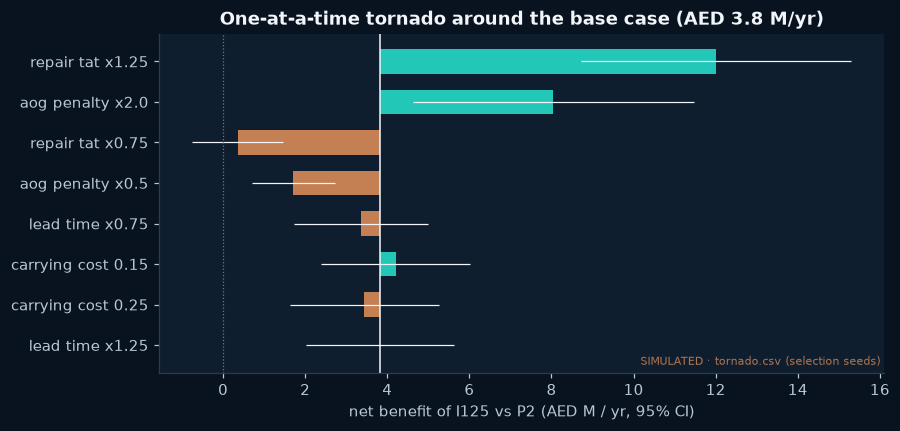

,label,net_benefit_mean,net_benefit_lo,net_benefit_hi,aog_reduction_mean,base_aog_hours,rec_aog_hours,significant
6,repair tat x1.25,12004010.0,8709597.0,15298422.0,385.0,553.0,168.0,True
2,aog penalty x2.0,8042212.0,4617989.0,11466436.0,143.0,235.0,92.0,True
5,repair tat x0.75,355942.0,-748041.0,1459924.0,45.0,102.0,57.0,False
1,aog penalty x0.5,1712962.0,707405.0,2718519.0,143.0,235.0,92.0,True
7,lead time x0.75,3367272.0,1737425.0,4997119.0,132.0,219.0,87.0,True
3,carrying cost 0.15,4201564.0,2393426.0,6009703.0,143.0,235.0,92.0,True
4,carrying cost 0.25,3443861.0,1634938.0,5252783.0,143.0,235.0,92.0,True
8,lead time x1.25,3822156.0,2008091.0,5636221.0,144.0,250.0,106.0,True


rule's pick under one-at-a-time changes (selection): [('aog_penalty', 'x0.5', 'I110'), ('aog_penalty', 'x2.0', 'B150'), ('carrying_cost', '0.15', 'I125'), ('carrying_cost', '0.25', 'I125')]
settings where I125's lead over P2 is NOT significant in cost: ['repair tat x0.75']


In [11]:
tor = pd.read_csv(ROOT / "outputs/frontier/tornado.csv")
base = tor[tor.factor == "base case"].iloc[0]
t = tor[(tor.factor != "base case") & (~tor.factor.str.contains("expedite"))].copy()
t["label"] = t.factor.str.replace("_", " ") + " " + t.setting.astype(str)
t = t.iloc[np.argsort(-abs(t.net_benefit_mean - base.net_benefit_mean).values)]
fig, ax = plt.subplots(figsize=(8.5, 4))
y = np.arange(len(t))
ax.barh(y, (t.net_benefit_mean - base.net_benefit_mean) / 1e6, left=base.net_benefit_mean / 1e6,
        color=[TEAL if v > base.net_benefit_mean else COPPER for v in t.net_benefit_mean], height=0.6)
ax.errorbar(t.net_benefit_mean / 1e6, y, xerr=[(t.net_benefit_mean - t.net_benefit_lo) / 1e6, (t.net_benefit_hi - t.net_benefit_mean) / 1e6],
            fmt="none", ecolor=ICE, lw=0.8)
ax.axvline(base.net_benefit_mean / 1e6, color=ICE, lw=1); ax.axvline(0, color=SLATE, lw=0.8, ls=":")
ax.set_yticks(y); ax.set_yticklabels(t.label); ax.invert_yaxis()
ax.set(xlabel="net benefit of I125 vs P2 (AED M / yr, 95% CI)", title=f"One-at-a-time tornado around the base case (AED {base.net_benefit_mean/1e6:.1f} M/yr)")
stamp(ax, "tornado.csv (selection seeds)"); plt.show()
t["significant"] = t.net_benefit_lo > 0
display(t[["label", "net_benefit_mean", "net_benefit_lo", "net_benefit_hi", "aog_reduction_mean", "base_aog_hours", "rec_aog_hours", "significant"]].round(0))
print("rule's pick under one-at-a-time changes (selection):", [(r["factor"], r["setting"], r["recommended"]) for r in fs["recommendation_stability"]])
ns = t[~t.significant].label.tolist()
print("settings where I125's lead over P2 is NOT significant in cost:", ns or "none")

I125's lead over P2 is **not significant in cost if repair is 25% faster**: a faster repair loop makes the extra float less valuable. The hourly rate scales the benefit, and the rule's recommended point shifts to **I110 at ×0.5** and **B150 at ×2** the hourly rate. The carrying rate barely matters. These are one-at-a-time changes; they say nothing about combinations.

### Post-plan stress check (D015, added after the main holdout)

At the user's request, and **after** the main v2 holdout, the frozen central-built candidates P0, P2 and I125 were evaluated on the same holdout seeds in the low- and high-stress worlds, paired against the central-built P2, with no re-selection. It is labelled post-plan because it was not part of the frozen run plan.

In [12]:
pp = load_json("outputs/holdout/postplan_i125_stress.json")
print(pp["note"])
rows = []
for wv, lst in pp["worlds"].items():
    r = next(x for x in lst if x["id"] == "I125")
    rows.append(dict(world=wv, P2_central_built_aog_h=r["aog_hours_mean"] - r["d_aog_hours_vs_base_mean"], I125_aog_h=r["aog_hours_mean"],
                     d_aog_h=f"{r['d_aog_hours_vs_base_mean']:+.0f} [{r['d_aog_hours_vs_base_lo']:+.0f}, {r['d_aog_hours_vs_base_hi']:+.0f}]",
                     d_total_cost=f"{aed_m(r['d_total_cost_vs_base_mean'])} [{aed_m(r['d_total_cost_vs_base_lo'])}, {aed_m(r['d_total_cost_vs_base_hi'])}]",
                     d_capital=aed_m(r["d_capital_vs_base_mean"]),
                     significant=r["d_aog_hours_vs_base_hi"] < 0 and r["d_total_cost_vs_base_hi"] < 0))
display(pd.DataFrame(rows).round(1))

Post-plan robustness check added after the main v2 holdout (D015); frozen central-built candidates; paired vs P2; no re-selection.


,world,P2_central_built_aog_h,I125_aog_h,d_aog_h,d_total_cost,d_capital,significant
0,low_stress,147.0,61.8,"-85 [-125, -45]","AED -1.7M [AED -2.9M, AED -0.4M]",AED 7.7M,True
1,high_stress,259.5,76.0,"-184 [-239, -128]","AED -5.0M [AED -6.8M, AED -3.1M]",AED 7.5M,True


Post-plan, I125 keeps a significant downtime and cost advantage over the central-built P2 in both stress worlds, smaller in the low-stress world and larger in the high-stress world. The extra AED 7.6M behaves like insurance against a harsher reliability world.

### Guardrails (stated before computing)

A planner does not stack stock far beyond what a stocking point actually sees. Two ceilings were applied to every optimised rotable allocation: **G1** the Palm total at a stocking point stays at or below the 99.5% fill quantile of its own pipeline; **G2** a station with at most 6 requests a year holds at most 1 unit. The as-built policies are evaluated unchanged, and their exceedances are reported:

In [13]:
g = fs["guardrails"]
print({k: g["config"][k] for k in ["fill_quantile", "low_rate_per_year", "low_rate_max_units"]}, "| overrides:", g["config"]["overrides"] or "none")
ex = {k: len(v) for k, v in g["pns_exceeding_by_candidate"].items() if k in ("P0", "P1", "P2", "P2_GUARD", "I110", "I125", "B150")}
print("PNs exceeding a guardrail:", ex)
pg = fp.loc["P2_GUARD"]
print(f"cost of the guardrails at P2's capital (P2_GUARD - P2, holdout): {pg.d_aog_hours_vs_base_mean:+.0f} h/yr "
      f"[{pg.d_aog_hours_vs_base_lo:+.0f}, {pg.d_aog_hours_vs_base_hi:+.0f}], capital {aed_m(pg.d_capital_vs_base_mean)}")

{'fill_quantile': 0.995, 'low_rate_per_year': 6.0, 'low_rate_max_units': 1} | overrides: none
PNs exceeding a guardrail: {'P2': 6, 'P0': 1, 'P1': 18, 'B150': 0, 'P2_GUARD': 0, 'I110': 0, 'I125': 0}
cost of the guardrails at P2's capital (P2_GUARD - P2, holdout): +21 h/yr [+14, +27], capital AED -0.6M


## 5. Levers: buy spares or cut repair TAT?

Per rotable, the optimiser compares buying 1–2 spares with paying the shop to cut 10 days of TAT (modelled, annual basis, at the P2 allocation; `outputs/frontier/levers.csv`, DERIVED).

buying 1 spare is cheaper per avoided downtime hour than a 10-day TAT cut for 18 of 21 rotables with a modelled reduction from both levers


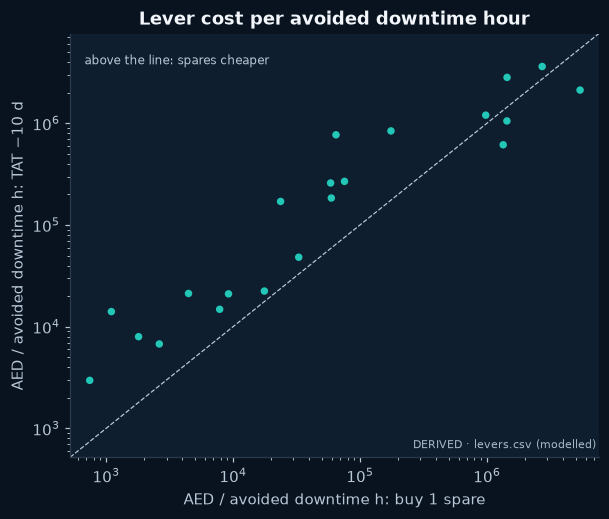

· GN-32-R037: buying 1 spares avoids 5 AOG h/yr for AED 4,071/yr, vs 4 h/yr for AED 12,031/yr by cutting TAT (tat_cut_10d).
· GN-27-R032: buying 1 spares avoids 4 AOG h/yr for AED 33,925/yr, vs 3 h/yr for AED 49,738/yr by cutting TAT (tat_cut_10d).
· GN-27-R006: buying 1 spares avoids 3 AOG h/yr for AED 27,621/yr, vs 3 h/yr for AED 58,868/yr by cutting TAT (tat_cut_10d).
· GN-32-R015: buying 1 spares avoids 3 AOG h/yr for AED 3,115/yr, vs 3 h/yr for AED 35,500/yr by cutting TAT (tat_cut_10d).
simulated on the holdout: TAT -10 d on the top 6 PNs (built on P2 within guardrails) = +7 h/yr [-3, +16] vs P2


In [14]:
lv = pd.read_csv(ROOT / "outputs/frontier/levers.csv")
w = lv.pivot_table(index="pn", columns="lever", values=["aog_hours_reduction", "annual_cost_aed"])
w.columns = [f"{a}|{b}" for a, b in w.columns]
w["cost_per_h_buy1"] = w["annual_cost_aed|buy_1"] / w["aog_hours_reduction|buy_1"].where(w["aog_hours_reduction|buy_1"] > 0)
w["cost_per_h_tat"] = w["annual_cost_aed|tat_cut_10d"] / w["aog_hours_reduction|tat_cut_10d"].where(w["aog_hours_reduction|tat_cut_10d"] > 0)
w = w.dropna(subset=["cost_per_h_buy1", "cost_per_h_tat"])
print(f"buying 1 spare is cheaper per avoided downtime hour than a 10-day TAT cut for {(w.cost_per_h_buy1 < w.cost_per_h_tat).sum()} of {len(w)} rotables "
      f"with a modelled reduction from both levers")
fig, ax = plt.subplots(figsize=(6.2, 5))
ax.scatter(w.cost_per_h_buy1, w.cost_per_h_tat, color=TEAL, s=24, edgecolor="none")
lim = [min(w.cost_per_h_buy1.min(), w.cost_per_h_tat.min()) * 0.7, max(w.cost_per_h_buy1.max(), w.cost_per_h_tat.max()) * 1.4]
ax.plot(lim, lim, color=TITANIUM, ls="--", lw=0.8)
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="AED / avoided downtime h: buy 1 spare",
       ylabel="AED / avoided downtime h: TAT −10 d", title="Lever cost per avoided downtime hour")
ax.text(lim[0] * 1.3, lim[1] / 2, "above the line: spares cheaper", color=TITANIUM, fontsize=8)
stamp(ax, "levers.csv (modelled)", "DERIVED"); plt.show()
for s in fs["lever_findings"]["tat_vs_buy_1"][:4]:
    print("·", s)
lt = fp.loc["LEV_TAT10_TOP6"]
print(f"simulated on the holdout: TAT -10 d on the top 6 PNs (built on P2 within guardrails) = {lt.d_aog_hours_vs_base_mean:+.0f} h/yr "
      f"[{lt.d_aog_hours_vs_base_lo:+.0f}, {lt.d_aog_hours_vs_base_hi:+.0f}] vs P2")

Per avoided downtime hour, buying a spare is the cheaper lever for most rotables in the model; a TAT cut wins on only a few. Simulated on the holdout, a 10-day TAT cut on the top 6 PNs does not beat P2 significantly. Repair-shop TAT is a second-order lever next to positioning in this world (although a faster repair loop does shrink I125's lead over P2, section 4).

## 6. Dependence on the AOG recovery routes

Every policy, P0 included, leans on the AOG recovery routes (ASSUMED odds and response times in `config/assumptions.yaml: aog_sourcing`): robbery at AUH (engineering/quality approval required), local borrow at outstations, exchange/loan by fleet type, and local buy for consumables and expendables. In practice that means access to an AOG exchange/loan market and to borrow agreements. Switching the routes off is a **structural stress, not a calibrated scenario** (selection seeds):

,"material AOG h/yr, routes on",routes off,multiple
P0,1727.4,42068.4,24.4
P2,235.2,18315.2,77.9
I125,92.2,11076.2,120.2


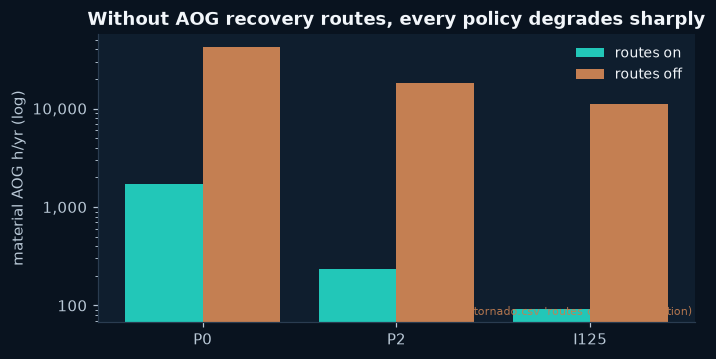

Every policy here, P0/P1/P2 included, relies on the v2 AOG-desk routes (V2-SIM-5/14, config aog_sourcing, ASSUMED): robbery at AUH (engineering/quality approval required), local borrow at outstations and exchange/loan by fleet, retried every 72 h for rotables, plus local buy for C/E; in practice this means access to an AOG exchange/loan market and to borrow agreements. Borrowed units never join the owned pool. With the routes switched off (tornado row 'aog_desk_expedite off'), expected material-related downtime rises sharply for every policy, so the frontier is conditional on those markets existing at the assumed availability.


In [15]:
off = tor[tor.factor.str.contains("expedite")].iloc[0]
dep = pd.DataFrame({"material AOG h/yr, routes on": {"P0": base.p0_base_aog_hours, "P2": base.base_aog_hours, "I125": base.rec_aog_hours},
                    "routes off": {"P0": off.p0_base_aog_hours, "P2": off.base_aog_hours, "I125": off.rec_aog_hours}})
dep["multiple"] = dep["routes off"] / dep["material AOG h/yr, routes on"]
display(dep.round(1))
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(3)
ax.bar(x - 0.2, dep.iloc[:, 0], width=0.4, color=TEAL, label="routes on")
ax.bar(x + 0.2, dep.iloc[:, 1], width=0.4, color=COPPER, label="routes off")
ax.set_xticks(x); ax.set_xticklabels(dep.index); ax.set(yscale="log", ylabel="material AOG h/yr (log)", title="Without AOG recovery routes, every policy degrades sharply")
ax.yaxis.set_major_formatter(mpl.ticker.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.legend(frameon=False); stamp(ax, "tornado.csv 'routes off' row (selection)"); plt.show()
print(fs["aog_desk_dependence"])

The ranking survives (P2 and I125 still beat P0 by a wide margin), but the absolute levels do not: the frontier is conditional on those markets existing at roughly the assumed availability. This is stated in `LIMITATIONS.md`.

## Summary

* **Core finding: Network Plan `P2`.** Network positioning, with 44 instead of 8 outstation rotables, cuts material AOG hours sharply against the Simple Rulebook (naive reference) `P0`. It is not a free move of stock: new rotables bought +68 units ≈ AED 8.4M assumed value; rotables removed −20 units ≈ AED 3.1M; net change in average simulated spare inventory +AED 0.6M. Removed stock is not cash back — it may be redeployed, consumed, exchanged or sold at a discount. It holds in all three worlds and across the ×0.5–×2 hourly-rate range (section 1). The cost is a slightly lower immediate fill on cheap count parts.
* **Frontier option: Network Plan + Extra Spares `I125`.** If you invest an additional AED 7.6M, I125 cuts downtime further, significantly on paired holdout seeds. Its lead over P2 is not significant in cost if repair is 25% faster, and the rule's pick shifts to I110 / B150 at ×0.5 / ×2 the hourly rate. The post-plan stress check keeps its advantage in both stress worlds.
* Selection and holdout agree, the guardrails cost little, spares beat TAT cuts on most rotables (yet faster repair can beat buying spares: with 25% shorter repair time, the extra-investment option loses its clear cost advantage), and every result depends on the AOG recovery routes being available.

*Independent educational simulation. Not an airline system or an approved maintenance, airworthiness or dispatch tool.*